# Differentiated Thyroid Cancer Recurrence: Statistical Analysis and Predictive Modeling
**Research question:** Can demographic and clinical characteristics help predict differentiated thyroid cancer recurrence?

**Dataset:** [UCI Machine Learning Repository, dataset 915](https://archive.ics.uci.edu/dataset/915/differentiated+thyroid+cancer+recurrence)

**Important:** This is an educational retrospective analysis, not a validated clinical decision tool. The dataset may include variables observed after diagnosis. In particular, `Response` is excluded from the primary analysis to avoid using post-treatment information when answering a diagnosis-time prediction question.

Run cells in order in Google Colab. The first data cell reads the CSV in the repository, or downloads the original archive when online.

## 1. Setup and reproducibility
**Enhancement 1:** Centralized configuration and fixed random seed. This makes experiments easier to reproduce and rerun.

In [1]:
import io, zipfile, urllib.request, warnings, re
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance
SEED = 42
TEST_SIZE = 0.25
sns.set_theme(style='whitegrid')
np.random.seed(SEED)
print('Setup complete')

Setup complete


## 2. Import and validate data
**Enhancement 2:** Flexible local-file/archive loading with explicit validation, normalized column names, duplicate reporting, and clear failure messages. The repository's `data/` folder is preferred to ensure repeatability.

In [2]:
DATA_PATH = Path('data/Thyroid_Diff.csv')
ARCHIVE_URL = 'https://archive.ics.uci.edu/static/public/915/differentiated+thyroid+cancer+recurrence.zip'

def load_dataset(path=DATA_PATH):
    if path.exists():
        print(f'Reading local dataset: {path}')
        return pd.read_csv(path)
    print('Local CSV not found; downloading original UCI archive...')
    try:
        with urllib.request.urlopen(ARCHIVE_URL, timeout=30) as response:
            raw = response.read()
        with zipfile.ZipFile(io.BytesIO(raw)) as z:
            csv_names = [name for name in z.namelist() if name.lower().endswith('.csv')]
            if not csv_names:
                raise ValueError('No CSV file found in the UCI archive.')
            with z.open(csv_names[0]) as f:
                data = pd.read_csv(f)
        path.parent.mkdir(parents=True, exist_ok=True)
        data.to_csv(path, index=False)
        print(f'Saved {path}')
        return data
    except Exception as exc:
        raise RuntimeError('Dataset unavailable. Download the CSV from the UCI page and place it at data/Thyroid_Diff.csv, or upload the repository data folder to Colab.') from exc

raw_df = load_dataset()
print('Original shape:', raw_df.shape)
print('Original columns:', raw_df.columns.tolist())
raw_df.head()

Reading local dataset: data/Thyroid_Diff.csv
Original shape: (383, 17)
Original columns: ['Age', 'Gender', 'Smoking', 'Hx Smoking', 'Hx Radiothreapy', 'Thyroid Function', 'Physical Examination', 'Adenopathy', 'Pathology', 'Focality', 'Risk', 'T', 'N', 'M', 'Stage', 'Response', 'Recurred']


,Age,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,F,No,No,No,Euthyroid,Single nodular goiter-left,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Indeterminate,No
1,34,F,No,Yes,No,Euthyroid,Multinodular goiter,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
2,30,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
3,62,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
4,62,F,No,No,No,Euthyroid,Multinodular goiter,No,Micropapillary,Multi-Focal,Low,T1a,N0,M0,I,Excellent,No


In [3]:
def normalize_name(name):
    return re.sub(r'_+', '_', re.sub(r'[^a-z0-9]+', '_', str(name).strip().lower())).strip('_')

df = raw_df.copy()
df.columns = [normalize_name(c) for c in df.columns]
if len(set(df.columns)) != len(df.columns):
    raise ValueError('Duplicate column names after normalization; inspect the original CSV.')
if 'recurred' not in df.columns:
    raise ValueError(f'Expected target column "Recurred". Found: {df.columns.tolist()}')
if df.empty:
    raise ValueError('Dataset is empty.')
for c in df.select_dtypes(include=['object', 'string']).columns:
    df[c] = df[c].astype('string').str.strip().replace({'': pd.NA, '?': pd.NA, 'nan': pd.NA})
print('Exact duplicate rows:', df.duplicated().sum())
print('Missing values by column:')
print(df.isna().sum().sort_values(ascending=False).to_string())
print('Target values:', df['recurred'].value_counts(dropna=False).to_dict())

Exact duplicate rows: 19
Missing values by column:
age                     0
gender                  0
smoking                 0
hx_smoking              0
hx_radiothreapy         0
thyroid_function        0
physical_examination    0
adenopathy              0
pathology               0
focality                0
risk                    0
t                       0
n                       0
m                       0
stage                   0
response                0
recurred                0
Target values: {'No': 275, 'Yes': 108}


## 3. Cleaning, leakage review, and feature engineering
**Enhancement 3:** Explicit exclusion of treatment response (potential target leakage), duplicate removal, target validation, and an age-group feature for descriptive analysis. The modeling age variable remains continuous to preserve information.

In [4]:
df = df.drop_duplicates().copy()
#Exclude records without a valid target rather than silently assuming their label.
target_text = df['recurred'].astype('string').str.strip().str.lower()
target_map = {'yes': 1, 'no': 0, '1': 1, '0': 0, 'true': 1, 'false': 0}
y_all = target_text.map(target_map)
if y_all.isna().any():
    raise ValueError(f'Unknown/missing recurrence labels: {df.loc[y_all.isna(), "recurred"].unique().tolist()}')
df['recurrence_binary'] = y_all.astype(int)
if df['recurrence_binary'].nunique() != 2:
    raise ValueError('Both recurrence classes are required for binary classification.')
if 'age' in df.columns:
    df['age'] = pd.to_numeric(df['age'], errors='coerce')
    df.loc[~df['age'].between(0, 110), 'age'] = np.nan
    df['age_group'] = pd.cut(df['age'], bins=[-np.inf, 30, 45, 60, np.inf], labels=['≤30', '31–45', '46–60', '>60'])
leakage_cols = [c for c in df.columns if c in {'response', 'recurred', 'recurrence_binary', 'age_group'}]
X = df.drop(columns=leakage_cols)
y = df['recurrence_binary']
print('Excluded from modeling:', leakage_cols)
print('Modeling features:', X.columns.tolist())
print('Final rows:', len(df))

Excluded from modeling: ['response', 'recurred', 'recurrence_binary', 'age_group']
Modeling features: ['age', 'gender', 'smoking', 'hx_smoking', 'hx_radiothreapy', 'thyroid_function', 'physical_examination', 'adenopathy', 'pathology', 'focality', 'risk', 't', 'n', 'm', 'stage']
Final rows: 364


## 4. Descriptive statistics and visual exploration
**Enhancement 4:** Automated recurrence-rate plots across available clinical variables, including outcome imbalance and stratified age distribution.

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,364.0,NaN,NaN,NaN,41.25,15.31436,15.0,30.0,38.0,52.0,82.0
gender,364,2,F,293,NaN,NaN,NaN,NaN,NaN,NaN,NaN
smoking,364,2,No,315,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hx_smoking,364,2,No,336,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hx_radiothreapy,364,2,No,357,NaN,NaN,NaN,NaN,NaN,NaN,NaN
thyroid_function,364,5,Euthyroid,313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
physical_examination,364,5,Multinodular goiter,135,NaN,NaN,NaN,NaN,NaN,NaN,NaN
adenopathy,364,6,No,258,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pathology,364,4,Papillary,271,NaN,NaN,NaN,NaN,NaN,NaN,NaN
focality,364,2,Uni-Focal,228,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Class distribution: {0: 256, 1: 108}
Recurrence prevalence: 29.7%


/tmp/ipykernel_4022/3758351206.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['No recurrence','Recurrence'])


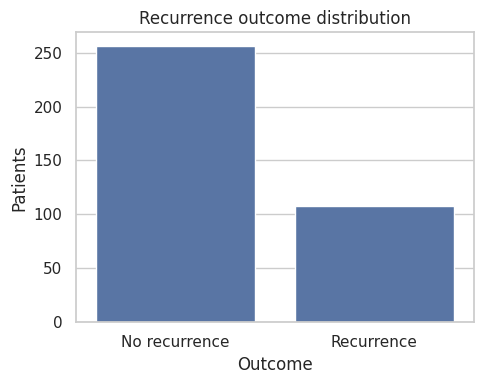

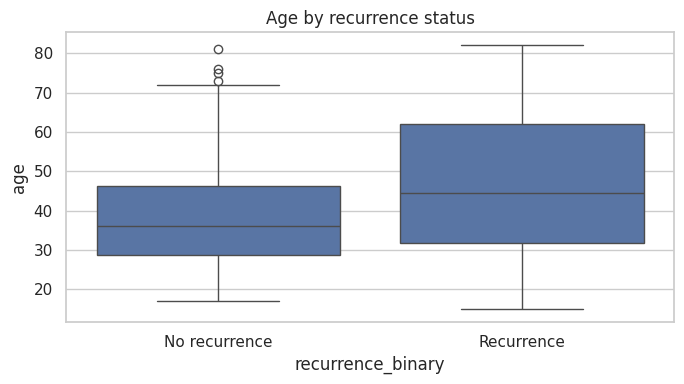

In [5]:
display(df.describe(include='all').T)
counts = y.value_counts().sort_index()
print('Class distribution:', counts.to_dict())
print('Recurrence prevalence:', f'{y.mean():.1%}')
fig, ax = plt.subplots(figsize=(5,4))
sns.countplot(data=df, x='recurrence_binary', order=[0,1], ax=ax)
ax.set_xticklabels(['No recurrence','Recurrence'])
ax.set(title='Recurrence outcome distribution', xlabel='Outcome', ylabel='Patients')
plt.tight_layout(); plt.show()
if 'age' in df:
    plt.figure(figsize=(7,4))
    sns.boxplot(data=df, x='recurrence_binary', y='age', order=[0,1])
    plt.xticks([0,1], ['No recurrence','Recurrence']); plt.title('Age by recurrence status')
    plt.tight_layout(); plt.show()

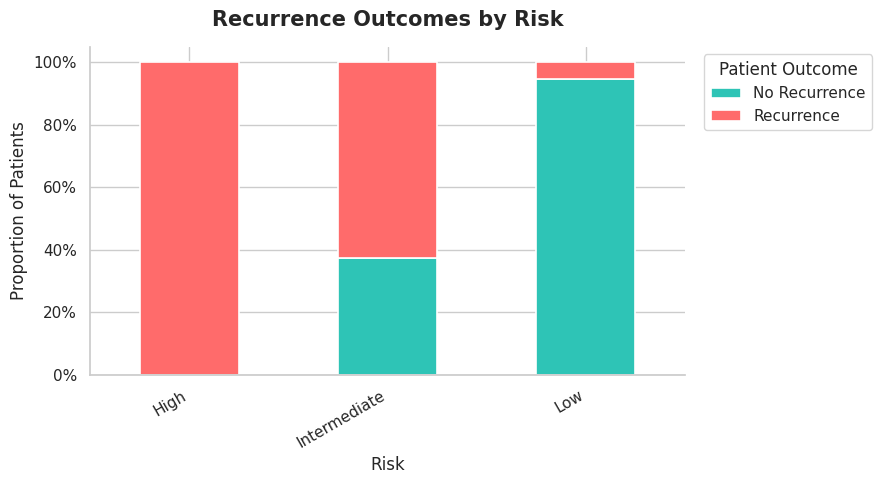

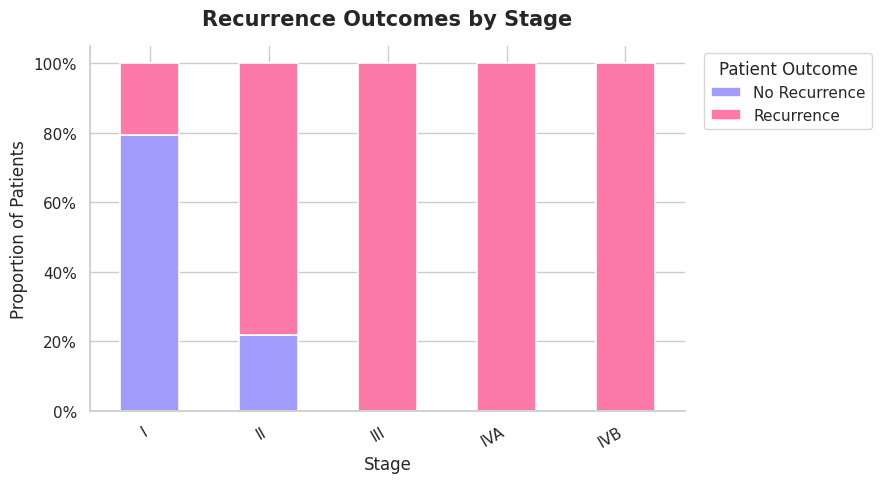

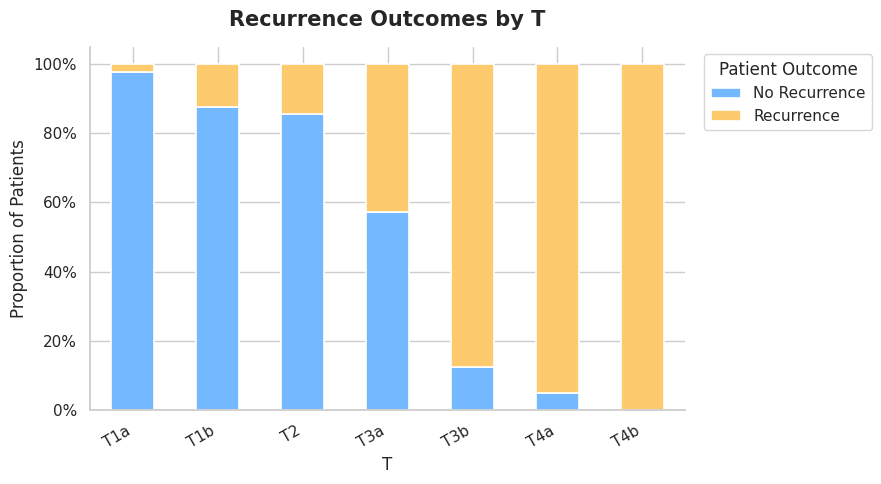

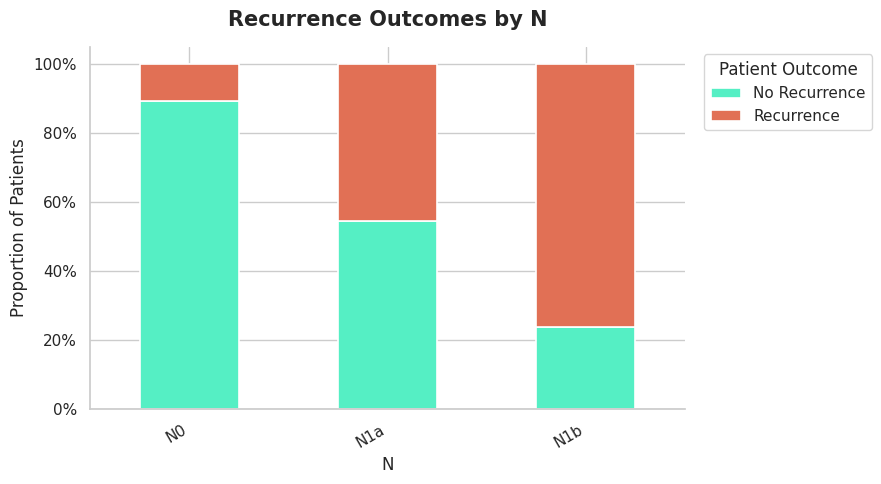

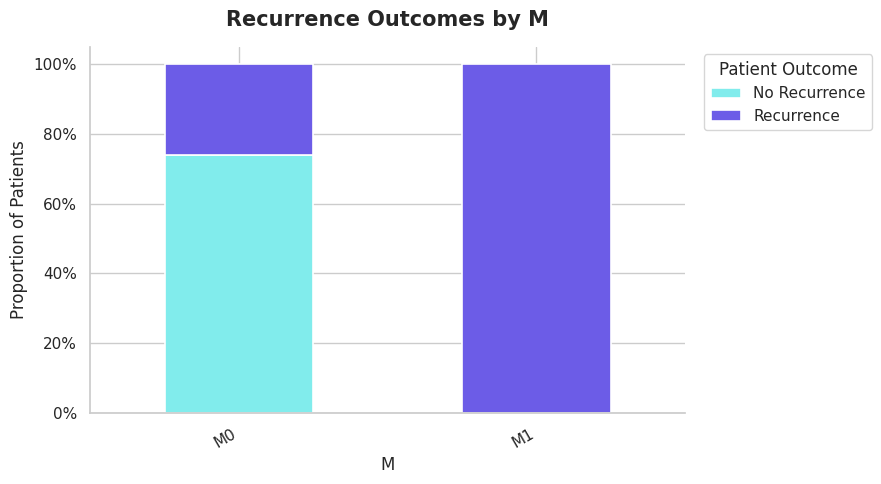

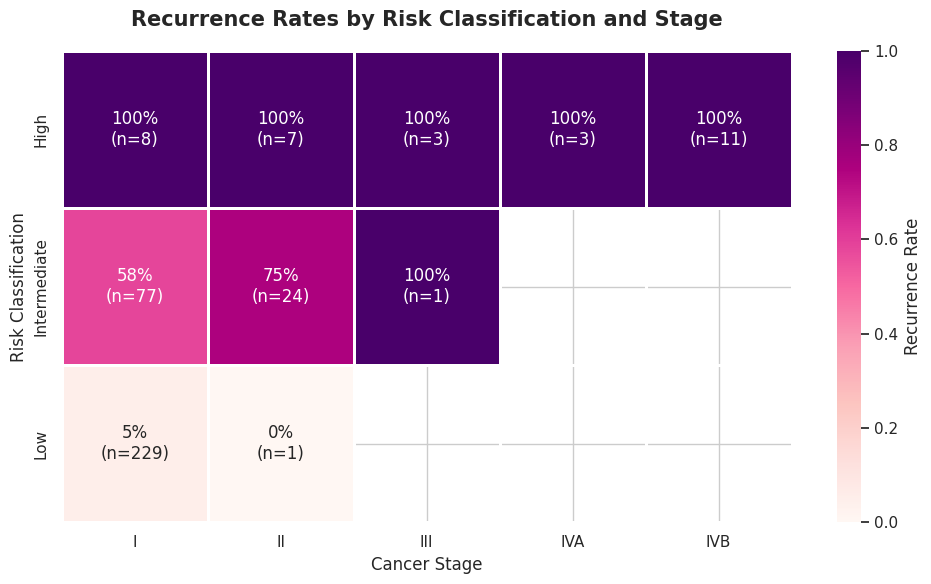

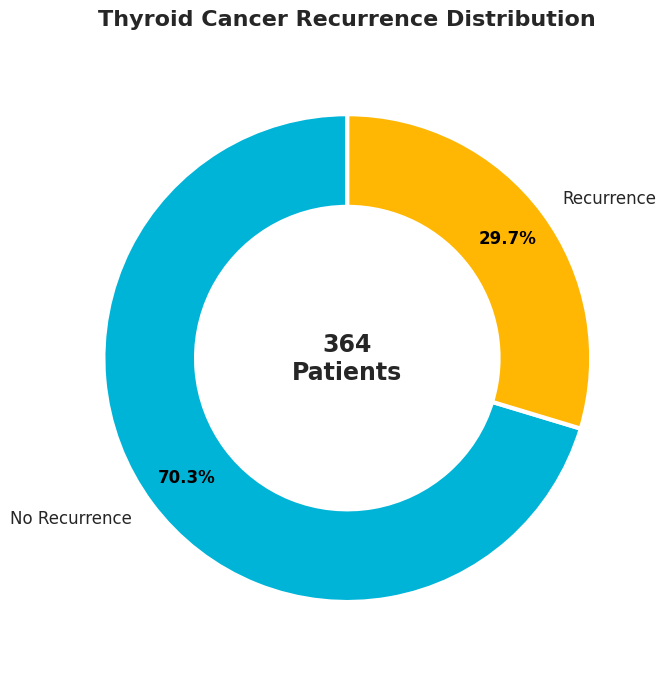

In [6]:
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid", context="notebook")

#1. STACKED BAR CHARTS
features = [c for c in ['risk', 'stage', 't', 'n', 'm'] if c in df.columns]

color_palettes = [
    ['#2EC4B6', '#FF6B6B'],
    ['#A29BFE', '#FD79A8'],
    ['#74B9FF', '#FDCB6E'],
    ['#55EFC4', '#E17055'],
    ['#81ECEC', '#6C5CE7']
]

for i, feature in enumerate(features):
    proportions = pd.crosstab(
        df[feature].fillna('Missing'),
        df['recurrence_binary'],
        normalize='index'
    ).reindex(columns=[0, 1], fill_value=0)

    proportions.columns = ['No Recurrence', 'Recurrence']

    ax = proportions.plot(
        kind='bar', stacked=True, figsize=(9, 5),
        color=color_palettes[i],
        edgecolor='white', linewidth=1.2
    )

    ax.set_title(f'Recurrence Outcomes by {feature.title()}',
                 fontsize=15, fontweight='bold', pad=15)
    ax.set_ylabel('Proportion of Patients')
    ax.set_xlabel(feature.title())
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(title='Patient Outcome', bbox_to_anchor=(1.02, 1),
              loc='upper left')

    plt.xticks(rotation=30, ha='right')
    sns.despine()
    plt.tight_layout()
    plt.show()

#2. CLINICAL RECURRENCE HEATMAP
if {'risk', 'stage', 'recurrence_binary'}.issubset(df.columns):
    heatmap_data = df.pivot_table(
        index='risk', columns='stage',
        values='recurrence_binary',
        aggfunc='mean', observed=True
    )

    counts = df.pivot_table(
        index='risk', columns='stage',
        values='recurrence_binary',
        aggfunc='count', observed=True
    ).reindex_like(heatmap_data).fillna(0)

    labels = heatmap_data.copy().astype(object)

    for i in range(heatmap_data.shape[0]):
        for j in range(heatmap_data.shape[1]):
            rate = heatmap_data.iloc[i, j]
            n = int(counts.iloc[i, j])
            labels.iloc[i, j] = (
                f'{rate:.0%}\n(n={n})' if pd.notna(rate) else ''
            )

    plt.figure(figsize=(10, 6))
    sns.heatmap(
        heatmap_data, annot=labels, fmt='',
        cmap='RdPu', vmin=0, vmax=1,
        linewidths=2, linecolor='white',
        cbar_kws={'label': 'Recurrence Rate'}
    )

    plt.title('Recurrence Rates by Risk Classification and Stage',
              fontsize=15, fontweight='bold', pad=18)
    plt.xlabel('Cancer Stage')
    plt.ylabel('Risk Classification')
    plt.tight_layout()
    plt.show()

#3. OVERALL RECURRENCE DONUT CHART
counts = df['recurrence_binary'].value_counts().reindex([0, 1], fill_value=0)

colors = ['#00B4D8', '#FFB703']

fig, ax = plt.subplots(figsize=(7, 7))
wedges, texts, autotexts = ax.pie(
    counts,
    labels=['No Recurrence', 'Recurrence'],
    colors=colors, autopct='%1.1f%%',
    startangle=90, pctdistance=0.82,
    wedgeprops={'width': 0.38, 'edgecolor': 'white', 'linewidth': 3},
    textprops={'fontsize': 12}
)

plt.setp(autotexts, fontweight='bold', color='black')
ax.text(0, 0, f'{counts.sum()}\nPatients',
        ha='center', va='center', fontsize=17, fontweight='bold')
ax.set_title('Thyroid Cancer Recurrence Distribution',
             fontsize=16, fontweight='bold', pad=20)

plt.tight_layout()
plt.show()





## 5. Inferential statistical analysis
**Enhancement 5:** Automated Chi-square tests for categorical predictors, Cramér's V effect sizes, and a Mann–Whitney U test for age. Tests are exploratory and do not establish causation. Sparse cells can weaken Chi-square approximations; p-values are unadjusted for multiple testing.

In [7]:
def cramers_v(table):
    chi2, _, _, _ = chi2_contingency(table)
    n = table.to_numpy().sum()
    denom = min(table.shape[0]-1, table.shape[1]-1)
    return float(np.sqrt((chi2/n)/denom)) if n > 0 and denom > 0 else np.nan

plot_vars = [c for c in ['risk', 'stage', 't', 'n', 'm'] if c in df.columns]

test_results = []
for feature in plot_vars:
    if feature == 'age_group':
        continue
    table = pd.crosstab(df[feature], y)
    if table.shape[0] < 2 or table.shape[1] < 2:
        continue
    chi2, pval, dof, expected = chi2_contingency(table)
    test_results.append({'feature':feature, 'test':'Chi-square', 'p_value':pval, 'effect_size_cramers_v':cramers_v(table), 'expected_cells_below_5':int((expected<5).sum())})
results_tests = pd.DataFrame(test_results)
if not results_tests.empty:
    display(results_tests.sort_values('p_value'))
if 'age' in df:
    a = df.loc[y.eq(0), 'age'].dropna()
    b = df.loc[y.eq(1), 'age'].dropna()
    if len(a) and len(b):
        stat, pval = mannwhitneyu(a,b,alternative='two-sided')
        print(f'Age Mann–Whitney U={stat:.1f}, p={pval:.4g}; group medians: {a.median():.1f} vs {b.median():.1f}')

,feature,test,p_value,effect_size_cramers_v,expected_cells_below_5
0,risk,Chi-square,4.037122e-43,0.732359,0
3,n,Chi-square,1.454426e-31,0.624612,0
2,t,Chi-square,8.370008e-26,0.599644,2
1,stage,Chi-square,8.999131e-19,0.499390,5
4,m,Chi-square,1.233844e-10,0.337291,0


Age Mann–Whitney U=10229.0, p=8.818e-05; group medians: 36.0 vs 44.5


## 6. Stratified split and leakage-safe preprocessing
**Enhancement 6:** Imputation, scaling, and one-hot encoding are fitted inside cross-validation pipelines, preventing training/test information leakage. Stratification preserves class proportions.

In [8]:
numeric_cols = X.select_dtypes(include='number').columns.tolist()
categorical_cols = [c for c in X.columns if c not in numeric_cols]
preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric_cols),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('encode', OneHotEncoder(handle_unknown='ignore'))]), categorical_cols)
], remainder='drop')
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=TEST_SIZE,random_state=SEED,stratify=y)
print('Training:', X_train.shape, 'Test:', X_test.shape)
print('Training recurrence rate:', round(y_train.mean(),3), 'Test recurrence rate:', round(y_test.mean(),3))

Training: (273, 15) Test: (91, 15)
Training recurrence rate: 0.297 Test recurrence rate: 0.297


## 7. Train and compare classifiers
**Enhancement 7:** Adds a majority-class baseline, stratified 5-fold cross-validation, and multiple complementary evaluation metrics (F1, precision, recall, ROC AUC, PR AUC). The untouched test set is evaluated once after model specification.

In [9]:
models = {
    'Majority baseline': Pipeline([('prep',preprocessor),('model',DummyClassifier(strategy='most_frequent'))]),
    'Logistic regression': Pipeline([('prep',preprocessor),('model',LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED))]),
    'Random forest': Pipeline([('prep',preprocessor),('model',RandomForestClassifier(n_estimators=300,min_samples_leaf=2,class_weight='balanced',random_state=SEED,n_jobs=-1))])
}
min_class = int(y_train.value_counts().min())
if min_class < 2:
    raise ValueError('Insufficient examples of the minority class for stratified cross-validation.')
cv = StratifiedKFold(n_splits=min(5,min_class), shuffle=True, random_state=SEED)
scoring = {'f1':'f1', 'recall':'recall', 'precision':'precision', 'roc_auc':'roc_auc', 'average_precision':'average_precision'}
cv_rows=[]
for name, pipeline in models.items():
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1, error_score='raise')
    row={'model':name}
    for metric in scoring:
        row[f'cv_{metric}_mean']=np.mean(scores[f'test_{metric}'])
        row[f'cv_{metric}_sd']=np.std(scores[f'test_{metric}'])
    cv_rows.append(row)
cv_results=pd.DataFrame(cv_rows).sort_values('cv_f1_mean',ascending=False)
display(cv_results.round(3))

,model,cv_f1_mean,cv_f1_sd,cv_recall_mean,cv_recall_sd,cv_precision_mean,cv_precision_sd,cv_roc_auc_mean,cv_roc_auc_sd,cv_average_precision_mean,cv_average_precision_sd
2,Random forest,0.787,0.040,0.826,0.074,0.755,0.035,0.934,0.014,0.881,0.049
1,Logistic regression,0.779,0.062,0.826,0.074,0.740,0.070,0.934,0.020,0.888,0.041
0,Majority baseline,0.000,0.000,0.000,0.000,0.000,0.000,0.500,0.000,0.297,0.007



 Majority baseline 
               precision    recall  f1-score   support

           0       0.70      1.00      0.83        64
           1       0.00      0.00      0.00        27

    accuracy                           0.70        91
   macro avg       0.35      0.50      0.41        91
weighted avg       0.49      0.70      0.58        91



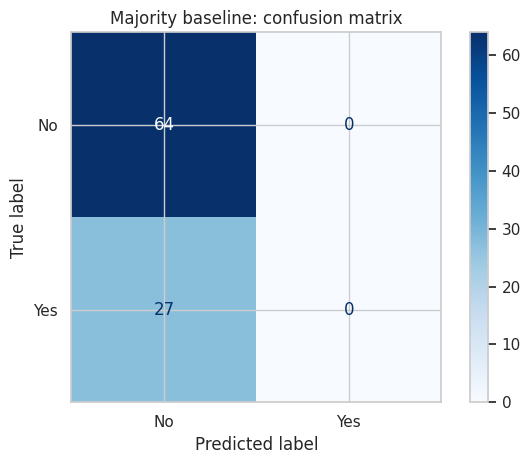


 Logistic regression 
               precision    recall  f1-score   support

           0       0.92      0.86      0.89        64
           1       0.71      0.81      0.76        27

    accuracy                           0.85        91
   macro avg       0.81      0.84      0.82        91
weighted avg       0.86      0.85      0.85        91



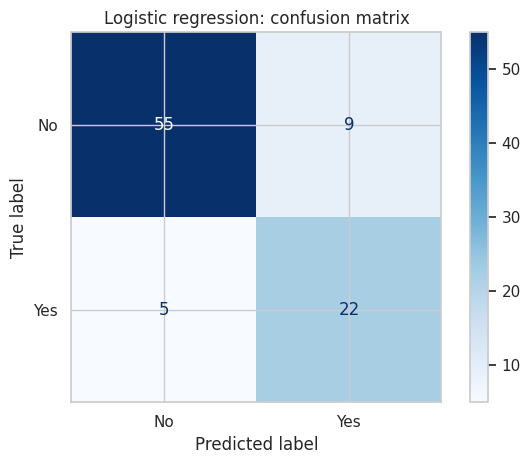


 Random forest 
               precision    recall  f1-score   support

           0       0.91      0.91      0.91        64
           1       0.78      0.78      0.78        27

    accuracy                           0.87        91
   macro avg       0.84      0.84      0.84        91
weighted avg       0.87      0.87      0.87        91



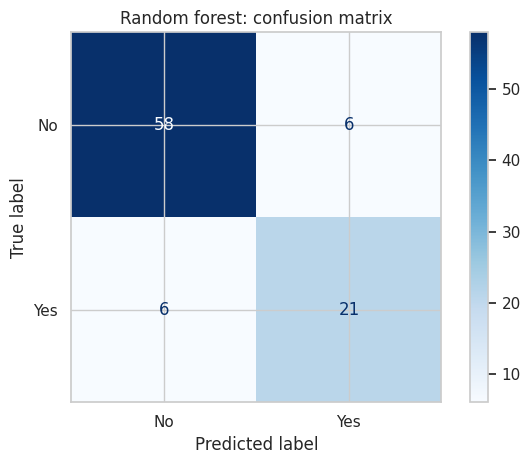

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
2,Random forest,0.868,0.778,0.778,0.778,0.917,0.869
1,Logistic regression,0.846,0.710,0.815,0.759,0.887,0.839
0,Majority baseline,0.703,0.000,0.000,0.000,0.500,0.297


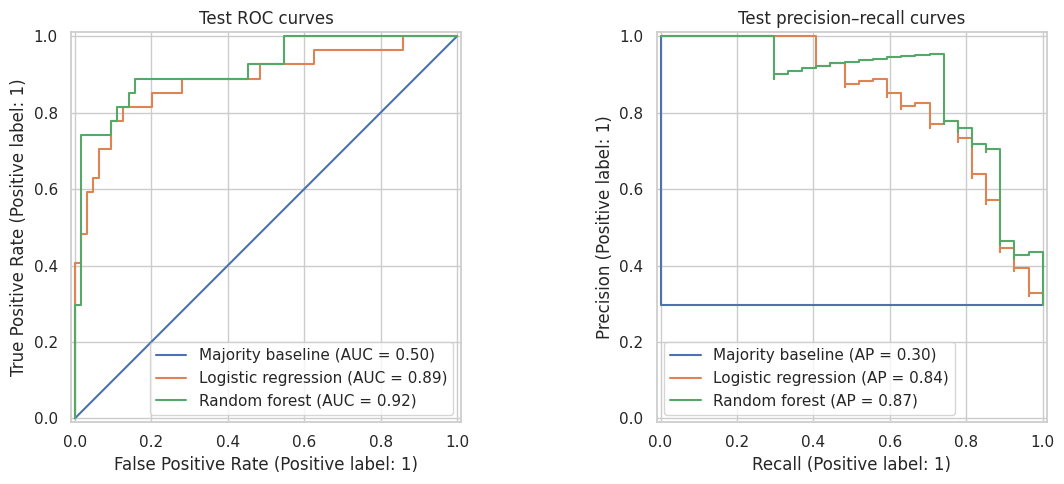

In [10]:
test_rows=[]
for name, pipeline in models.items():
    pipeline.fit(X_train,y_train)
    pred=pipeline.predict(X_test)
    proba=pipeline.predict_proba(X_test)[:,1]
    test_rows.append({'model':name, 'accuracy':accuracy_score(y_test,pred), 'precision':precision_score(y_test,pred,zero_division=0), 'recall':recall_score(y_test,pred,zero_division=0), 'f1':f1_score(y_test,pred,zero_division=0), 'roc_auc':roc_auc_score(y_test,proba), 'pr_auc':average_precision_score(y_test,proba)})
    print('\n',name,'\n',classification_report(y_test,pred,zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=['No','Yes'],cmap='Blues')
    plt.title(f'{name}: confusion matrix'); plt.tight_layout(); plt.show()
test_results=pd.DataFrame(test_rows).sort_values('f1',ascending=False)
display(test_results.round(3))
fig, axes=plt.subplots(1,2,figsize=(12,5))
for name,pipeline in models.items():
    RocCurveDisplay.from_estimator(pipeline,X_test,y_test,ax=axes[0],name=name)
    PrecisionRecallDisplay.from_estimator(pipeline,X_test,y_test,ax=axes[1],name=name)
axes[0].set_title('Test ROC curves'); axes[1].set_title('Test precision–recall curves')
plt.tight_layout();plt.show()

## 8. Interpret predictors
**Enhancement 8:** Held-out permutation importance on original columns, avoiding misleading interpretation of individual one-hot encoded levels. Importance measures model reliance, not causal influence. Small test samples produce uncertain rankings.

Permutation importance: Logistic regression


,feature,mean_f1_decrease,sd
10,risk,0.126,0.053
7,adenopathy,0.044,0.024
14,stage,0.014,0.012
5,thyroid_function,0.013,0.015
12,n,0.013,0.011
6,physical_examination,0.009,0.014
0,age,0.004,0.010
13,m,0.001,0.003
3,hx_smoking,0.000,0.000
2,smoking,0.000,0.000


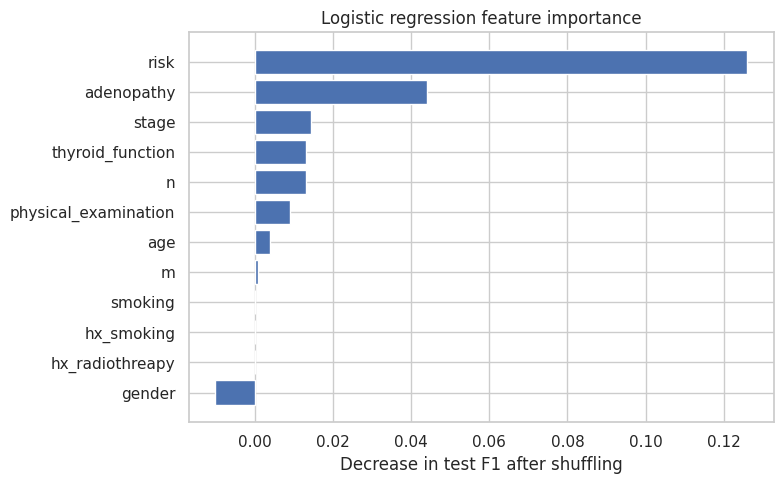

Permutation importance: Random forest


,feature,mean_f1_decrease,sd
10,risk,0.143,0.043
12,n,0.050,0.026
7,adenopathy,0.030,0.029
14,stage,0.007,0.015
1,gender,0.005,0.007
8,pathology,0.003,0.006
13,m,0.001,0.004
0,age,0.000,0.018
3,hx_smoking,0.000,0.000
4,hx_radiothreapy,0.000,0.000


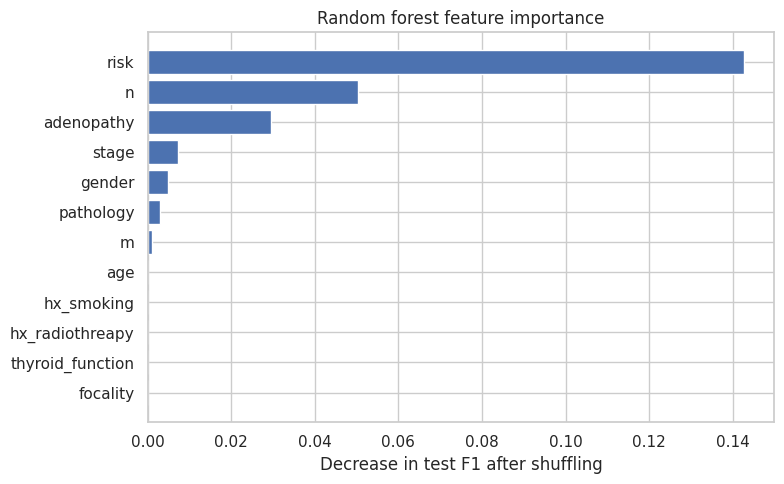

In [11]:
for name in ['Logistic regression','Random forest']:
    fitted=models[name]
    imp=permutation_importance(fitted,X_test,y_test,n_repeats=15,random_state=SEED,scoring='f1',n_jobs=-1)
    importance=pd.DataFrame({'feature':X.columns,'mean_f1_decrease':imp.importances_mean,'sd':imp.importances_std}).sort_values('mean_f1_decrease',ascending=False)
    print(f'Permutation importance: {name}')
    display(importance.head(12).round(3))
    top=importance.head(12).sort_values('mean_f1_decrease')
    plt.figure(figsize=(8,5));plt.barh(top['feature'],top['mean_f1_decrease'])
    plt.xlabel('Decrease in test F1 after shuffling');plt.title(name+' feature importance')
    plt.tight_layout();plt.show()

## 9. Automated findings and limitations


In [13]:
best_cv = cv_results.iloc[0]
print(f"Best cross-validated F1: {best_cv['model']} ({best_cv['cv_f1_mean']:.3f} ± {best_cv['cv_f1_sd']:.3f}).")
print(f"Observed recurrence rate: {y.mean():.1%} across {len(df)} records.")
print('Held-out comparison:')
print(test_results[['model','f1','recall','precision','roc_auc','pr_auc']].round(3).to_string(index=False))
print('\nInterpretation: Favor cross-validated performance for model selection; treat test performance as a final estimate, not a tuning target.')
print('Limitations: observational single-source data; possible selection bias; uncertain timing of staging/risk variables; small sample; no external validation; association is not causation.')
print('Clinical use would require temporal verification, external validation, calibration, fairness assessment, and prospective review.')

Best cross-validated F1: Random forest (0.787 ± 0.040).
Observed recurrence rate: 29.7% across 364 records.
Held-out comparison:
              model    f1  recall  precision  roc_auc  pr_auc
      Random forest 0.778   0.778      0.778    0.917   0.869
Logistic regression 0.759   0.815      0.710    0.887   0.839
  Majority baseline 0.000   0.000      0.000    0.500   0.297

Interpretation: Favor cross-validated performance for model selection; treat test performance as a final estimate, not a tuning target.
Limitations: observational single-source data; possible selection bias; uncertain timing of staging/risk variables; small sample; no external validation; association is not causation.
Clinical use would require temporal verification, external validation, calibration, fairness assessment, and prospective review.



## Model Evaluation and Interpretation

### Cross-Validation Results
Random Forest was the best-performing model during cross-validation, achieving an average F1 score of **0.787 ± 0.040**. This suggests that the model performed relatively consistently across the validation folds and was effective at balancing precision and recall.

### Recurrence Distribution
The dataset contained **364 patient records**, with an observed thyroid cancer recurrence rate of **29.7%**. This indicates some class imbalance, as approximately 70% of patients did not experience recurrence. Because of this imbalance, F1 score, recall, and precision were emphasized over accuracy alone when evaluating model performance.

### Model Performance Comparison

| Model | F1 Score | Recall | Precision | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|
| **Random Forest** | **0.778** | 0.778 | **0.778** | **0.917** | **0.869** |
| Logistic Regression | 0.759 | **0.815** | 0.710 | 0.887 | 0.839 |
| Majority Baseline | 0.000 | 0.000 | 0.000 | 0.500 | 0.297 |

Random Forest achieved the highest overall F1 score (0.778), outperforming Logistic Regression (0.759) on the held-out test set. It also achieved higher ROC-AUC and PR-AUC scores, suggesting stronger overall discrimination between patients with and without recurrence.

However, Logistic Regression achieved a higher recall of **0.815**, compared to **0.778** for Random Forest. This means Logistic Regression identified a greater proportion of patients who actually experienced recurrence, although it also had lower precision.

Both models substantially outperformed the majority-class baseline, which failed to identify any recurrence cases.

### Interpretation of Findings
The results suggest that demographic and clinical variables contain useful information for predicting thyroid cancer recurrence. Random Forest performed slightly better overall, which may indicate that nonlinear relationships or interactions between clinical variables are useful for this classification problem.

At the same time, Logistic Regression remained competitive and achieved better recall. In a healthcare setting, recall is particularly important because failing to identify a patient who may experience recurrence could have serious consequences.

Although Random Forest was the strongest model based on cross-validated F1 score, Logistic Regression may be worth considering in situations where identifying as many recurrence cases as possible is the primary goal.

Feature importance analysis can help identify which clinical variables contributed most to the predictions. However, these relationships should be interpreted as predictive associations rather than evidence that specific factors cause recurrence.

### Limitations
Several limitations should be considered when interpreting these findings:

- The dataset contained only **364 records**, which limits the sample size available for training and testing.
- The data came from a single source, potentially limiting how well the models would generalize to other patient populations.
- The recurrence outcome was somewhat imbalanced, with only **29.7%** of patients experiencing recurrence.
- Certain clinical variables, such as staging and risk classification, may require further verification to confirm when they were recorded relative to the prediction point.
- Neither model was externally validated using an independent clinical dataset.
- The observed relationships are associations and should not be interpreted as causal effects.

### Conclusion
This analysis demonstrates that machine learning models can identify patterns associated with differentiated thyroid cancer recurrence using demographic and clinical information.

**Random Forest was the strongest overall model**, achieving a cross-validated F1 score of **0.787 ± 0.040** and a held-out test F1 score of **0.778**. Logistic Regression also performed well, particularly in recall, where it identified a greater proportion of recurrence cases.

The results highlight an important tradeoff between overall predictive performance and sensitivity to recurrence cases. While Random Forest provided the best balance of precision and recall, Logistic Regression may be preferable when minimizing missed recurrence cases is the priority.



## 10. Enhancement log
| # | What was modified | Why | How it improves the workflow |
|---|---|---|---|
| 1 | Centralized random seed and split configuration | Ensure consistency | Reproducible reruns |
| 2 | Robust CSV/archive loader and schema/label validation | Catch malformed inputs | Clear failures and portable execution |
| 3 | Removed post-treatment response and created age groups | Limit leakage; aid EDA | More defensible diagnosis-time analysis |
| 4 | Automated stratified recurrence-rate charts | Compare clinical subgroups | Faster exploratory review |
| 5 | Added Chi-square, Cramér's V and Mann–Whitney tests | Quantify exploratory associations | Inferential evidence beyond plots |
| 6 | Preprocessing inside sklearn pipelines | Prevent preprocessing leakage | Valid cross-validation and test estimates |
| 7 | Baseline, stratified CV, ROC AUC and PR AUC | Compare models more rigorously | Class-imbalance-aware evaluation |
| 8 | Original-column permutation importance | Interpret predictions | Comparable feature reliance across models |
| 9 | Dynamically generated results summary | Avoid invented performance values | Transparent, repeatable reporting |

